# 📝 Natural Language Processing (NLP) - Text Classification
**Task:** Classify text data into categories (e.g., sentiment analysis).  
**Requirements:** Preprocess text, use TF-IDF, train Logistic Regression / Naive Bayes, evaluate with precision/recall/f1.  
**Tools:** `Python`, `nltk`, `scikit-learn`, `pandas`

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load Data
try:
    df = pd.read_csv('data/sentiment_reviews.csv')
    print('✅ Data loaded successfully')
    text_col = 'Text'
    label_col = 'Sentiment'
except:
    # Fallback dummy data
    df = pd.DataFrame({'Text': ['Great!', 'Terrible', 'Okay', 'Loved it', 'Hated it'], 'Sentiment': ['Pos', 'Neg', 'Neu', 'Pos', 'Neg']})
    text_col, label_col = 'Text', 'Sentiment'

# Clean data
df = df.dropna(subset=[text_col, label_col])
df[label_col] = df[label_col].str.strip()
display(df[[text_col, label_col]].head())

✅ Data loaded successfully


,Text,Sentiment
0,Enjoying a beautiful day at the park! ...,Positive
1,Traffic was terrible this morning. ...,Negative
2,Just finished an amazing workout! 💪 ...,Positive
3,Excited about the upcoming weekend getaway! ...,Positive
4,Trying out a new recipe for dinner tonight. ...,Neutral


In [2]:
# Preprocessing: TF-IDF Vectorization
vectorizer = TfidfVectorizer(stop_words='english', max_features=1000)
X = vectorizer.fit_transform(df[text_col])
y = df[label_col]

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'✅ Data split: Train {X_train.shape}, Test {X_test.shape}')

✅ Data split: Train (585, 1000), Test (147, 1000)


In [3]:
# Train Models
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"\n--- {name} ---")
    print(f"Accuracy: {accuracy_score(y_test, preds):.2f}")
    print(classification_report(y_test, preds))


--- Naive Bayes ---
Accuracy: 0.15
                      precision    recall  f1-score   support

          Acceptance       0.00      0.00      0.00         2
          Admiration       0.00      0.00      0.00         2
           Affection       0.00      0.00      0.00         1
         Ambivalence       0.00      0.00      0.00         1
               Anger       0.00      0.00      0.00         1
        Anticipation       0.00      0.00      0.00         1
             Arousal       0.00      0.00      0.00         3
                 Awe       0.00      0.00      0.00         2
                 Bad       0.00      0.00      0.00         1
            Betrayal       0.00      0.00      0.00         3
              Bitter       0.00      0.00      0.00         1
          Bitterness       0.00      0.00      0.00         1
         Bittersweet       0.00      0.00      0.00         1
             Boredom       0.00      0.00      0.00         1
            Calmness       0.00  


--- Logistic Regression ---
Accuracy: 0.21
                      precision    recall  f1-score   support

          Acceptance       1.00      1.00      1.00         2
          Admiration       0.00      0.00      0.00         2
           Affection       0.00      0.00      0.00         1
         Ambivalence       0.00      0.00      0.00         1
               Anger       0.00      0.00      0.00         1
        Anticipation       0.00      0.00      0.00         1
             Arousal       0.00      0.00      0.00         3
                 Awe       0.00      0.00      0.00         2
                 Bad       0.00      0.00      0.00         1
            Betrayal       0.00      0.00      0.00         3
              Bitter       0.00      0.00      0.00         1
          Bitterness       0.00      0.00      0.00         1
         Bittersweet       0.00      0.00      0.00         1
             Boredom       0.00      0.00      0.00         1
            Calmness     

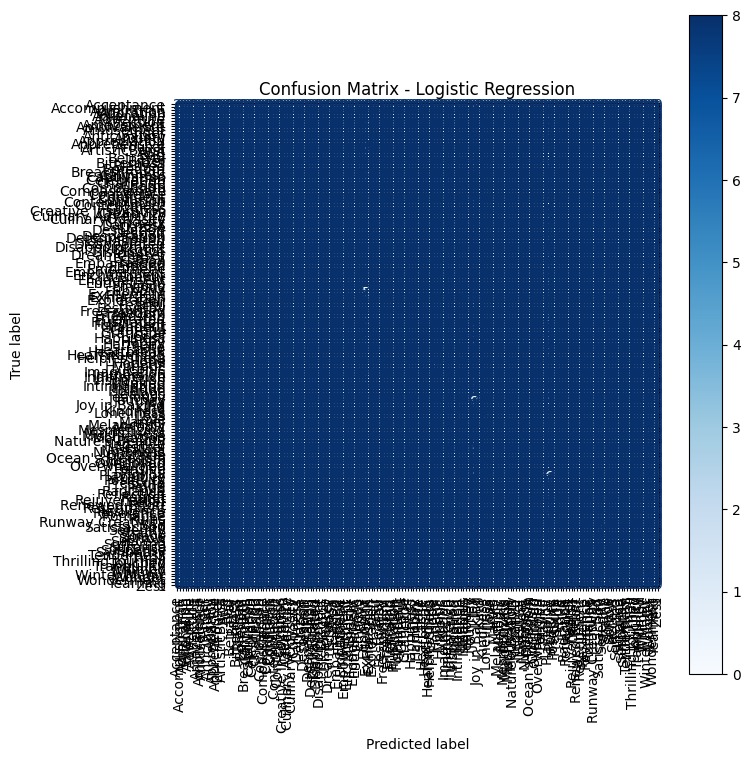

In [4]:
# Plot Confusion Matrix for Best Model (Logistic Regression)
best_model = models['Logistic Regression']
preds = best_model.predict(X_test)

cm = confusion_matrix(y_test, preds, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation='vertical')
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

In [5]:

import joblib
import os
import pandas as pd

os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save NLP models and vectorizer
joblib.dump(models['Logistic Regression'], 'models/logistic_nlp_model.pkl')
joblib.dump(models['Naive Bayes'], 'models/naive_bayes_model.pkl')
joblib.dump(vectorizer, 'models/tfidf_vectorizer.pkl')

# Save predictions
output_df = pd.DataFrame({'Text': df.loc[y_test.index, text_col], 'Actual': y_test, 'Predicted': preds})
output_df.to_csv('outputs/nlp_predictions.csv', index=False)
print('✅ Saved models and outputs successfully!')


✅ Saved models and outputs successfully!
